# Lab 10 — Imitation and reinforcement learning on a patrol task

**Book sections:** [7.1](../../book/docs/chapters/07-decision-making/mdp.md)–[7.6](../../book/docs/chapters/07-decision-making/rl-finetuning.md).

**Goal.** A drone patrols a circular route around the depot yard, pushed by wind gusts. We collect expert
demonstrations and watch behavioural cloning drift off the route (compounding error), then fix it three ways:
noise-injected demonstrations (DART), interactive relabelling (DAgger), and reinforcement-learning fine-tuning
with a KL anchor to the cloned policy. Everything is vectorised in PyTorch: hundreds of episodes run in parallel.

**Runtime:** ≈3 min on CPU. **Downloads:** none. **GPU:** not needed. **Seed:** 0.

In [1]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from vlacourse.seed import set_seed

set_seed(0)
torch.set_num_threads(4)

## 1. The task: a vectorised POMDP-free patrol
State $\mathbf{s}=(x,y)$, route: the circle of radius $R=0.6$ around the origin, counter-clockwise.
Action: a velocity command in the unit disc. Dynamics: $\mathbf{s}_{t+1}=\mathbf{s}_t+v\,\mathbf{a}_t+\mathbf{w}_t$,
$v=0.03$ per step, with wind $\mathbf{w}_t\sim\mathcal{N}(0,\sigma_w^2I)$. **Path error** $=|\,\lVert\mathbf{s}\rVert-R\,|$.
The **expert** flies along the tangent and corrects radial errors proportionally:
$\mathbf{a}^\ast=\operatorname{normalise}\big(\hat{\mathbf{t}}+k\,(R-\lVert\mathbf{s}\rVert)\,\hat{\mathbf{r}}\big)$ — a stable
feedback controller that returns to the route from anywhere.

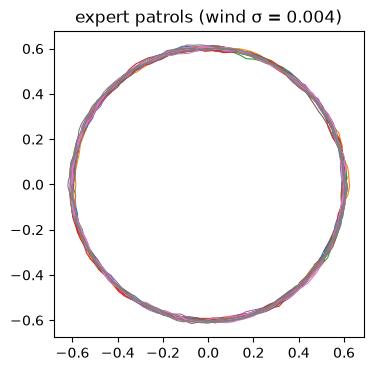

expert mean path error over 400 steps: 0.0054


In [2]:
R, V = 0.6, 0.03


def clip_unit(a):
    n = a.norm(dim=-1, keepdim=True).clamp(min=1.0)
    return a / n


def expert(s, k=8.0):
    r = s.norm(dim=-1, keepdim=True)
    radial = s / r                                          # unit vector away from the centre
    tangent = torch.stack([-radial[:, 1], radial[:, 0]], -1)   # counter-clockwise
    a = tangent + k * (R - r) * radial
    return a / a.norm(dim=-1, keepdim=True)                 # full speed


def step(s, a, wind=0.004, generator=None):
    return s + V * clip_unit(a) + wind * torch.randn(s.shape, generator=generator)


def path_error(s):
    return (s.norm(dim=-1) - R).abs()


def start_on_route(n, generator):
    ang = torch.rand(n, generator=generator) * 2 * math.pi
    return R * torch.stack([ang.cos(), ang.sin()], -1)


@torch.no_grad()
def rollout(policy, n=256, T=400, wind=0.004, seed=0):
    g = torch.Generator().manual_seed(seed)
    s = start_on_route(n, g)
    states, errs = [], []
    for _ in range(T):
        states.append(s)
        s = step(s, policy(s), wind, g)
        errs.append(path_error(s).mean().item())
    return torch.stack(states), errs


S_exp, e_exp = rollout(expert, n=8)
plt.figure(figsize=(4, 4))
for j in range(8):
    plt.plot(S_exp[:, j, 0], S_exp[:, j, 1], lw=0.8)
plt.gca().set_aspect("equal"); plt.title("expert patrols (wind σ = 0.004)"); plt.show()
print(f"expert mean path error over 400 steps: {sum(e_exp) / len(e_exp):.4f}")

## 2. Behavioural cloning
Demonstrations: expert rollouts of 200 steps from random points *on* the route, in almost calm air
(σ = 0.0005), so they rarely show a correction.
The policy is an MLP trained by MSE (the expert is deterministic and unimodal, so MSE is the right loss here —
book 6.1). We test it in the stronger wind of §1.

In [3]:
@torch.no_grad()
def demonstrations(n_demos, T=200, wind=0.0005, act_noise=0.0, seed=1):
    """Expert rollouts. With act_noise > 0 the executed action is perturbed but the label stays the
    expert's intended action (DART)."""
    g = torch.Generator().manual_seed(seed)
    s = start_on_route(n_demos, g)
    S, A = [], []
    for _ in range(T):
        a = expert(s)
        S.append(s); A.append(a)
        s = step(s, a + act_noise * torch.randn(a.shape, generator=g), wind, g)
    return torch.cat(S), torch.cat(A)


def mlp():
    return nn.Sequential(nn.Linear(2, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 2))


def train_bc(S, A, steps=2000, seed=0, net=None):
    torch.manual_seed(seed)
    net = net or mlp()
    opt = torch.optim.Adam(net.parameters(), 3e-3)
    for _ in range(steps):
        j = torch.randint(0, len(S), (256,))
        loss = ((net(S[j]) - A[j]) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return net, loss.item()


curves = {"expert": e_exp}
for n_demos in (5, 50):
    S, A = demonstrations(n_demos)
    net, loss = train_bc(S, A)
    _, curves[f"BC, {n_demos} demos"] = rollout(lambda s, net=net: net(s))
    print(f"BC on {n_demos:3d} demos ({len(S):6d} labels): training MSE {loss:.5f},   "
          f"closed-loop error  t=50: {curves[f'BC, {n_demos} demos'][49]:.3f}   t=400: {curves[f'BC, {n_demos} demos'][-1]:.3f}")
bc5 = train_bc(*demonstrations(5))[0]

BC on   5 demos (  1000 labels): training MSE 0.00004,   closed-loop error  t=50: 0.022   t=400: 0.060


BC on  50 demos ( 10000 labels): training MSE 0.00003,   closed-loop error  t=50: 0.023   t=400: 0.061


The training loss is tiny, yet in closed loop the policy drifts away from the route: small errors push it off
the narrow band the expert visited, where the network was never trained and has no reason to steer back
(book 7.3). Where do the demonstrations live, and where does BC go?

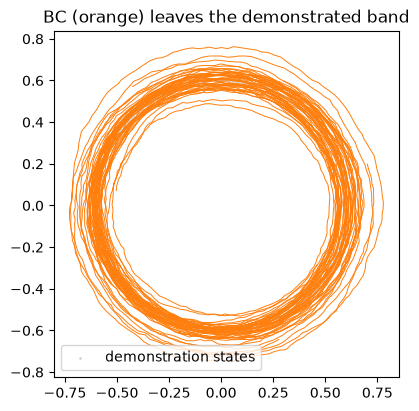

In [4]:
S5, _ = demonstrations(5)
S_bc, _ = rollout(lambda s: bc5(s), n=16)
plt.figure(figsize=(4.5, 4.5))
plt.scatter(S5[:, 0], S5[:, 1], s=1, c="lightgray", label="demonstration states")
for j in range(16):
    plt.plot(S_bc[:, j, 0], S_bc[:, j, 1], lw=0.7, c="tab:orange")
plt.gca().set_aspect("equal"); plt.title("BC (orange) leaves the demonstrated band"); plt.legend(loc="lower left")
plt.show()

## 3. Noise-injected demonstrations (DART)
Perturb the expert's *executed* action while recording its *intended* action. The demonstrations now contain
recoveries from small deviations.

In [5]:
S, A = demonstrations(5, act_noise=1.0)
net, _ = train_bc(S, A)
_, curves["DART σ=1.0, 5 demos"] = rollout(lambda s: net(s))
print(f"DART (σ = 1.0): error t=400 {curves['DART σ=1.0, 5 demos'][-1]:.3f}")

DART (σ = 1.0): error t=400 0.006


## 4. DAgger
Start from BC on 5 demos; each iteration rolls out the mixture of expert and learner (β = 0.5^i), labels every
visited state with the expert's action, aggregates and retrains (book 7.4).

In [6]:
S_d, A_d = demonstrations(5)
net = train_bc(S_d, A_d)[0]
dagger_err, labels = [], [len(S_d)]
for i in range(5):
    beta = 0.5 ** (i + 1)
    g = torch.Generator().manual_seed(100 + i)
    s = start_on_route(5, g)
    new_s, new_a = [], []
    with torch.no_grad():
        for _ in range(200):
            a_exp, a_pol = expert(s), net(s)
            new_s.append(s); new_a.append(a_exp)
            mix = (torch.rand(len(s), 1, generator=g) < beta).float()
            s = step(s, mix * a_exp + (1 - mix) * a_pol, 0.004, g)
    S_d, A_d = torch.cat([S_d] + new_s), torch.cat([A_d] + new_a)
    net = train_bc(S_d, A_d, net=net, steps=1000)[0]
    _, err = rollout(lambda s, net=net: net(s))
    dagger_err.append(err[-1]); labels.append(len(S_d))
    print(f"DAgger iteration {i + 1}: {len(S_d):5d} labels, error t=400 {err[-1]:.3f}")
curves["DAgger, 5 iterations"] = err
dagger_net = net

DAgger iteration 1:  2000 labels, error t=400 0.058


DAgger iteration 2:  3000 labels, error t=400 0.041


DAgger iteration 3:  4000 labels, error t=400 0.018


DAgger iteration 4:  5000 labels, error t=400 0.008


DAgger iteration 5:  6000 labels, error t=400 0.006


Same label budget for plain BC (6 × 1000 = 6000 labels = 30 demos) for a fair comparison:

In [7]:
net30 = train_bc(*demonstrations(30))[0]
_, curves["BC, 30 demos (same labels as DAgger)"] = rollout(lambda s: net30(s))
print(f"BC with 30 demos: error t=400 {curves['BC, 30 demos (same labels as DAgger)'][-1]:.3f}")

BC with 30 demos: error t=400 0.063


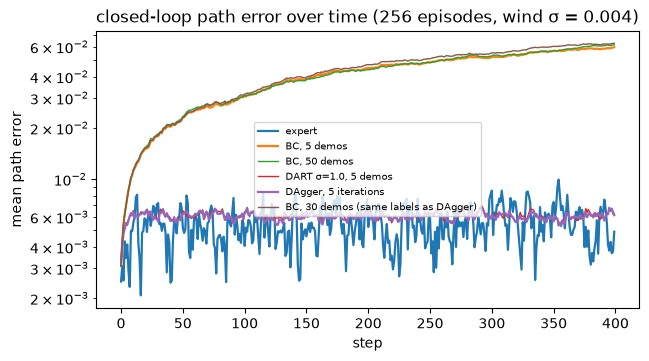

In [8]:
plt.figure(figsize=(7, 3.6))
for k, v in curves.items():
    plt.plot(v, label=k, lw=1.6 if k in ("expert", "BC, 5 demos", "DAgger, 5 iterations") else 1)
plt.xlabel("step"); plt.ylabel("mean path error"); plt.yscale("log"); plt.legend(fontsize=7)
plt.title("closed-loop path error over time (256 episodes, wind σ = 0.004)")
plt.show()

## 5. Reinforcement-learning fine-tuning: residual policies
Keep the 5-demo BC policy **frozen** and learn a residual correction on top of it by REINFORCE:
$\mathbf{a}\sim\mathcal{N}\big(\pi_\text{BC}(\mathbf{s})+\mathbf{r}_\phi(\mathbf{s}),\ \sigma^2I\big)$, reward $r_t=-10\cdot\text{path error}$,
episodes of 60 steps starting *near* the route (exploring starts: from exactly on the route the return is
dominated by random wind and carries almost no information about the actions). The baseline is the batch
mean of the return at each time step. Two residual families:

* a **network** $\mathbf{r}_\phi$ (2→64→2, last layer zero-initialised so that training starts *at* BC);
* a **4-parameter gain** $\mathbf{r}_W(\mathbf{s})=W_1(R-\lVert\mathbf{s}\rVert)\hat{\mathbf{r}}+W_2(R-\lVert\mathbf{s}\rVert)\hat{\mathbf{t}}$ (elementwise, $W_1,W_2\in\mathbb{R}^2$)
  acting on the radial error, initialised at zero.

A KL anchor to the BC policy becomes, for equal-variance Gaussians, a penalty $\beta\lVert\mathbf{r}\rVert^2/2\sigma^2$ on
the residual (book 7.6).

In [9]:
def start_near_route(n, g, spread=0.15):
    ang = torch.rand(n, generator=g) * 2 * math.pi
    r = R + spread * (2 * torch.rand(n, generator=g) - 1)
    return r[:, None] * torch.stack([ang.cos(), ang.sin()], -1)


class GainResidual(nn.Module):
    def __init__(self):
        super().__init__()
        self.W = nn.Parameter(torch.zeros(2, 2))

    def forward(self, s):
        r = s.norm(dim=-1, keepdim=True)
        rhat = s / r
        that = torch.stack([-rhat[:, 1], rhat[:, 0]], -1)
        e = R - r                                                      # signed radial error
        return (e * rhat) * self.W[0] + (e * that) * self.W[1]


def net_residual():
    net = nn.Sequential(nn.Linear(2, 64), nn.Tanh(), nn.Linear(64, 2))
    nn.init.zeros_(net[2].weight); nn.init.zeros_(net[2].bias)
    return net


def residual_reinforce(res, lr, beta_kl=0.0, updates=150, n=256, T=60, sigma=0.15, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(res.parameters(), lr)
    g = torch.Generator().manual_seed(seed)
    for it in range(updates):
        s = start_near_route(n, g)
        logps, rews, pens = [], [], []
        for _ in range(T):
            r_out = res(s)
            dist = torch.distributions.Normal(bc5(s).detach() + r_out, sigma)
            a = dist.sample()
            logps.append(dist.log_prob(a).sum(-1))
            pens.append((r_out ** 2).sum(-1) / (2 * sigma ** 2))                  # KL(pi || pi_BC)
            s = step(s, a, 0.004, g)
            rews.append(-10 * path_error(s))
        ret, Rt = [], torch.zeros(n)
        for r in reversed(rews):
            Rt = r + 0.95 * Rt
            ret.insert(0, Rt)
        ret = torch.stack(ret)
        adv = (ret - ret.mean(1, keepdim=True)).detach()                          # per-time-step baseline
        loss = -(torch.stack(logps) * adv).mean() + beta_kl * torch.stack(pens).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return res


for name, make, lr, beta_kl in [("residual network (4,226 params)", net_residual, 3e-3, 0.0),
                                ("residual gain (4 params)", GainResidual, 0.05, 0.0),
                                ("residual gain, KL anchor β=0.1", GainResidual, 0.05, 0.1)]:
    res = residual_reinforce(make(), lr, beta_kl)
    _, err = rollout(lambda s, res=res: bc5(s) + res(s))
    curves[f"RL: {name}"] = err
    extra = f"   W = {[round(w, 2) for w in res.W.data.flatten().tolist()]}" if isinstance(res, GainResidual) else ""
    print(f"{name:34s} error t=50 {err[49]:.3f}   t=400 {err[-1]:.3f}{extra}")

residual network (4,226 params)    error t=50 0.034   t=400 0.133


residual gain (4 params)           error t=50 0.008   t=400 0.008   W = [3.21, 3.04, -0.18, 0.15]


residual gain, KL anchor β=0.1     error t=50 0.008   t=400 0.008   W = [2.91, 2.77, 0.07, 0.33]


Same algorithm, same number of rollouts (150 × 256 episodes of 60 steps). The 4-parameter residual learns a
radial correction gain (≈3, against the expert's 8) and cuts the drift by almost an order of magnitude; the
residual *network* gets *worse* — its policy-gradient estimate is far too noisy for 4,000 parameters at this
sample budget, and noisy updates of a closed-loop controller are not harmless. Sample complexity grows
with the number of parameters the gradient must estimate. This is why RL fine-tuning of a billion-parameter VLA
touches as few parameters as possible (small heads, residuals, low-rank adapters) or uses the low-variance
reweighting methods of book 7.6. Here the KL anchor only shrinks the learned gains slightly (≈2.9 vs ≈3.2) at
the same error; with a less informative reward or a longer run, it is what stops the policy from drifting
arbitrarily far from the cloned behaviour.

## 6. Summary

In [10]:
print(f"{'policy':40s} {'error t=50':>10} {'error t=400':>12}")
for k, v in curves.items():
    print(f"{k:40s} {v[49]:10.3f} {v[-1]:12.3f}")

policy                                   error t=50  error t=400
expert                                        0.007        0.005
BC, 5 demos                                   0.022        0.060
BC, 50 demos                                  0.023        0.061
DART σ=1.0, 5 demos                           0.006        0.006
DAgger, 5 iterations                          0.006        0.006
BC, 30 demos (same labels as DAgger)          0.022        0.063
RL: residual network (4,226 params)           0.034        0.133
RL: residual gain (4 params)                  0.008        0.008
RL: residual gain, KL anchor β=0.1            0.008        0.008


## Exercises
1. Increase the evaluation wind to σ = 0.01. Which method degrades most? Why does DART's noise level matter?
2. Give the BC policy a short history (the last two states). Does it help here? When would it?
3. Replace the scripted expert in DAgger by a *noisy* expert (labels with σ = 0.2). How does the final error
   change? This models human labelling noise.
4. Implement reward-filtered BC (keep the best 20% of rollouts of the BC policy, fine-tune on them, repeat).
   How does it compare with residual REINFORCE after the same number of rollouts? And DART with noise
   σ = 0.1, 0.3 and 0.6 instead of 1.0?
5. Robotics: the patrol drone flies at 2 m/s around a 30 m-radius route. Using the per-step speed of this lab,
   what control rate does the simulation correspond to? With a VLA running at 5 Hz and 10-step chunks, how far
   does the drone fly open loop between observations?